# Student Perfomance Indicator
---

#### Life Cycle of Machine Learning Project

- Understand Problem Statement
- Data Collection
- Data Checks and Perform
- Exploratory Data Analysis
- Data Pre-Processing
- Model Training
- Choose Best Model

## 1) Problem Statement
---

project = effect of matrices on student performance like gender, parent level of education, Launch, Ethnicity and Test Preperation Course

## 2) Data Collection
---
- Dataset Source - https://www.kaggle.com/datasets/spscientist/students-performance-in-exams?datasetId=74977
- The data consists of 8 column and 1000 rows.

#### 2.1) Importing Libraries & Loading Data
---

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
import warnings
warnings.filterwarnings('ignore')

In [3]:
df = pd.read_csv('data/stud.csv')
dataset = df.copy()

#### 2.2) Data Information
---

In [4]:
df.head(3)

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race_ethnicity               1000 non-null   str  
 2   parental_level_of_education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test_preparation_course      1000 non-null   str  
 5   math_score                   1000 non-null   int64
 6   reading_score                1000 non-null   int64
 7   writing_score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 62.6 KB


In [6]:
df.shape

(1000, 8)

In [7]:
# for _ in df:
#     if _=="math_score":
#         break
#     else:
#         print(df[_].unique().tolist())
# for _ in df.iloc[:,-3:]:
#     if _ =="math_score":
#         min_val = df[_].min()
#         max_val = df[_].max()
#         print(f"{_} is {min_val} to {max_val}")

for col in df:
    if col in df.columns[-3:]:
        print(f"{col} is {df[col].min()} to {df[col].max()}")
    else:
        print(f"{col}: {df[col].unique().tolist()}")

gender: ['female', 'male']
race_ethnicity: ['group B', 'group C', 'group A', 'group D', 'group E']
parental_level_of_education: ["bachelor's degree", 'some college', "master's degree", "associate's degree", 'high school', 'some high school']
lunch: ['standard', 'free/reduced']
test_preparation_course: ['none', 'completed']
math_score is 0 to 100
reading_score is 17 to 100
writing_score is 10 to 100


## 3) Data Checks to Perform
---

- Check Missing values
- Check Duplicates
- Check data type
- Check the number of unique values of each column
- Check statistics of data set

In [8]:
print(df.isna().sum())

gender                         0
race_ethnicity                 0
parental_level_of_education    0
lunch                          0
test_preparation_course        0
math_score                     0
reading_score                  0
writing_score                  0
dtype: int64


In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race_ethnicity               1000 non-null   str  
 2   parental_level_of_education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test_preparation_course      1000 non-null   str  
 5   math_score                   1000 non-null   int64
 6   reading_score                1000 non-null   int64
 7   writing_score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 62.6 KB


In [11]:
df.nunique()

gender                          2
race_ethnicity                  5
parental_level_of_education     6
lunch                           2
test_preparation_course         2
math_score                     81
reading_score                  72
writing_score                  77
dtype: int64

In [12]:
df.describe()

,math_score,reading_score,writing_score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


## 4) EDA
---

In [13]:
df.head(3)

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93


#### 4.1) Adding Total Score and Average Column

In [16]:
df['total_score'] = df['math_score'] + df["reading_score"] +	df["writing_score"]
df['average'] = df['total_score'] / 3

df.head(3)

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score,total_score,average
0,female,group B,bachelor's degree,standard,none,72,72,74,218,72.666667
1,female,group C,some college,standard,completed,69,90,88,247,82.333333
2,female,group B,master's degree,standard,none,90,95,93,278,92.666667


#### 4.2) Value Distribution (Frequency Count / Binning)

In [17]:
reading_full = df[df['reading_score'] == 100]['average'].count()
writing_full = df[df['writing_score'] == 100]['average'].count()
math_full = df[df['math_score'] == 100]['average'].count()

reading_less_20 = df[df['reading_score'] <= 20]['average'].count()
writing_less_20 = df[df['writing_score'] <= 20]['average'].count()
math_less_20 = df[df['math_score'] <= 20]['average'].count()

print(f'Number of students with less than 20 and full marks in Maths: {math_less_20} {math_full}')
print(f'Number of students with less than 20 and full marks in Writing: {writing_less_20} {writing_full}')
print(f'Number of students with less than 20 and full marks in Reading: {reading_less_20} {reading_full}')

Number of students with less than 20 and full marks in Maths: 4 7
Number of students with less than 20 and full marks in Writing: 3 14
Number of students with less than 20 and full marks in Reading: 1 17


#### 4.3) Visualization

> Female Performing Well

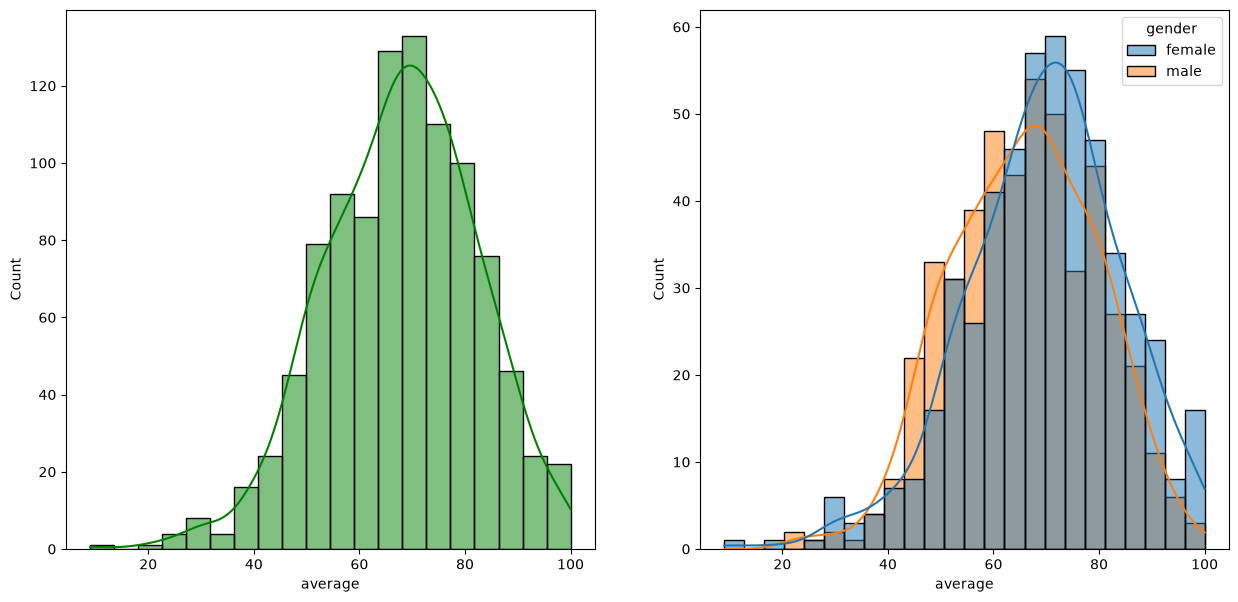

In [27]:
fig, axs = plt.subplots(1, 2, figsize=(15, 7))
plt.subplot(121)
sns.histplot(data=df,x='average',bins=20,kde=True,color='g')
plt.subplot(122)
sns.histplot(data=df,x='average',kde=True,hue='gender')
plt.show()

> compares average based on lunch type 
- Standard lunch helps perform well in exams.

<Axes: xlabel='average', ylabel='Count'>

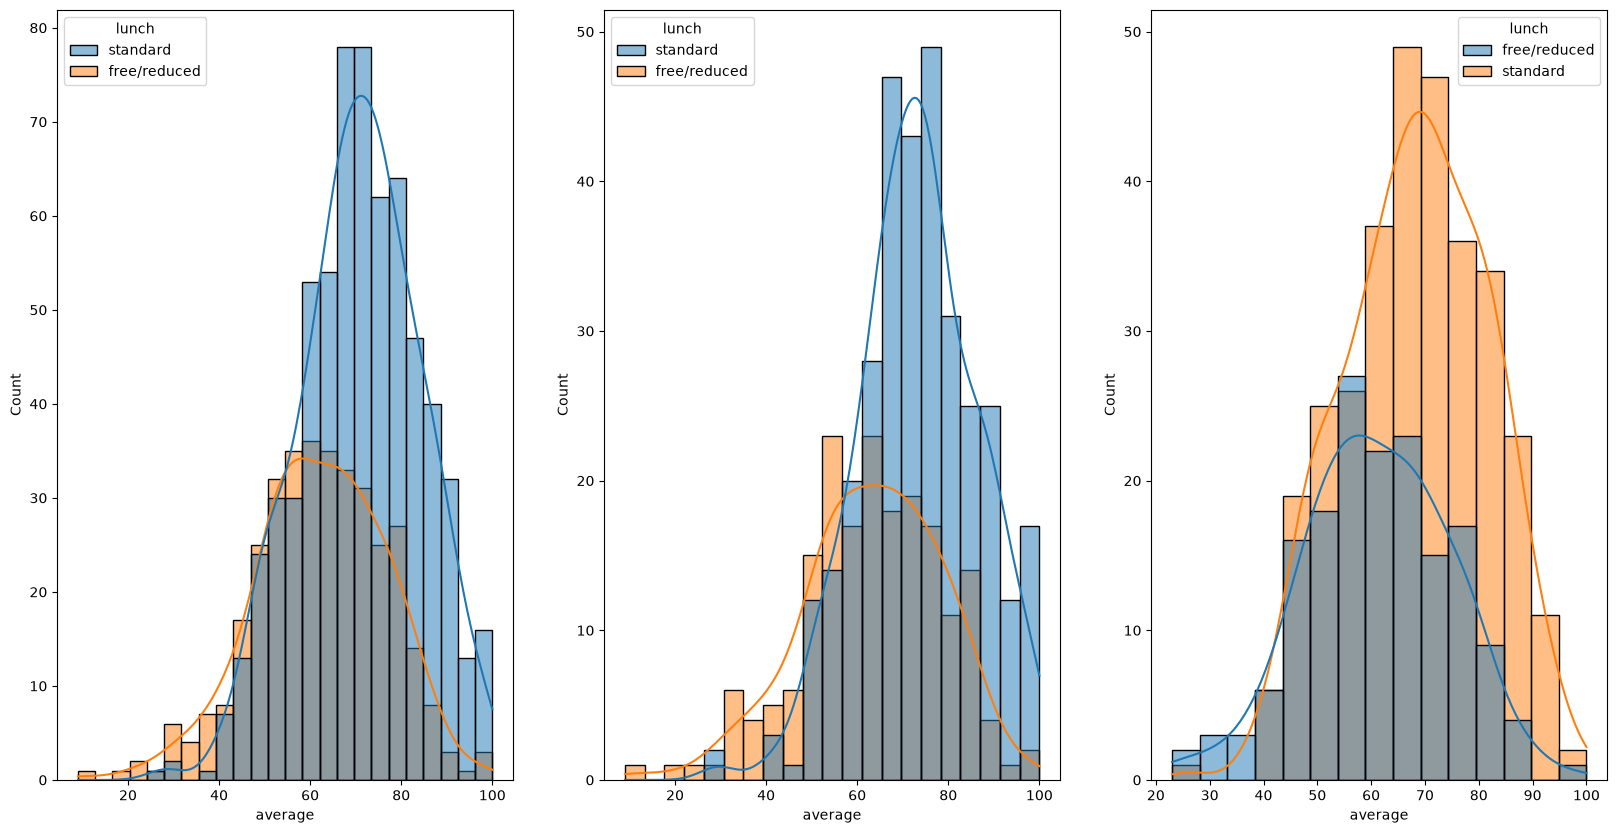

In [31]:
plt.close('all')

fig, ax = plt.subplots(1, 3, figsize=(20, 10))

sns.histplot(data=df, x='average', kde=True, hue='lunch', ax=ax[0])

sns.histplot(data=df[df.gender == 'female'], x='average', kde=True, hue='lunch', ax=ax[1])

sns.histplot(data=df[df.gender == 'male'], x='average', kde=True, hue='lunch', ax=ax[2])

> Parental Education Effect
- Parental edu. may some association with student perf, but no guarantee higher marks.

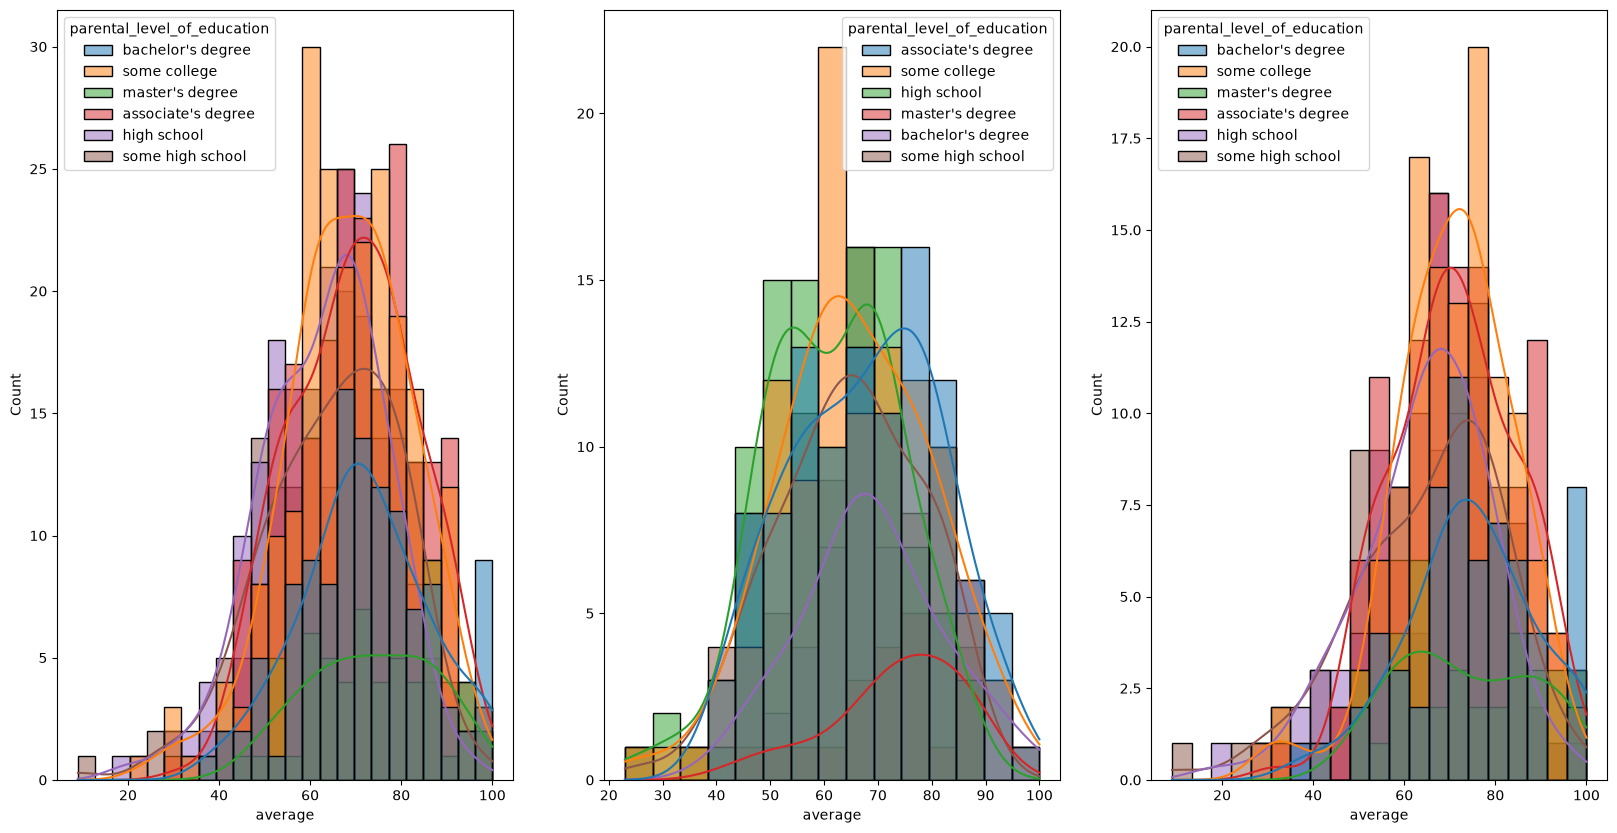

In [36]:
plt.close('all')
fig, ax = plt.subplots(1, 3, figsize=(20, 10))

sns.histplot(data=df,x='average',kde=True,hue='parental_level_of_education',ax=ax[0])

sns.histplot(data=df[df.gender=='male'],x='average',kde=True,hue='parental_level_of_education',ax=ax[1])

sns.histplot(data=df[df.gender=='female'],x='average',kde=True,hue='parental_level_of_education',ax=ax[2])
plt.show()

In [37]:
# Mean, Median and Student Count
parent_group = df.groupby('parental_level_of_education')['average'].agg(
    ['mean', 'median', 'count']
).sort_values(by='mean', ascending=False)

parent_group

,mean,median,count
parental_level_of_education,,,
master's degree,73.598870,73.333333,59
bachelor's degree,71.923729,71.166667,118
associate's degree,69.569069,69.666667,222
some college,68.476401,68.666667,226
some high school,65.108007,66.666667,179
high school,63.096939,65.000000,196
